## Importation des bibliothèques


In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_clean = pd.read_csv('df_clean.csv', nrows=500000)

print("Le fichier est chargé")
print(df_clean.head())

Le fichier est chargé
                 product_name department          aisle  order_id  \
0  Chocolate Sandwich Cookies     snacks  cookies cakes     23202   
1  Chocolate Sandwich Cookies     snacks  cookies cakes     24367   
2  Chocolate Sandwich Cookies     snacks  cookies cakes     24760   
3  Chocolate Sandwich Cookies     snacks  cookies cakes     25365   
4  Chocolate Sandwich Cookies     snacks  cookies cakes     26490   

   add_to_cart_order  reordered   user_id  order_dow  order_hour_of_day  \
0                3.0        0.0  162394.0        3.0               12.0   
1                2.0        1.0  148255.0        6.0               17.0   
2                5.0        1.0  205157.0        5.0               17.0   
3                9.0        1.0  181127.0        3.0               20.0   
4               14.0        1.0   92648.0        5.0               15.0   

   days_since_prior_order  
0                     7.0  
1                     6.0  
2                    25.0  


## Graphique, Top 10 des roduits les plus vendus

/tmp/ipykernel_25939/3212420787.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=best_products.values, y=best_products.index, palette='viridis')


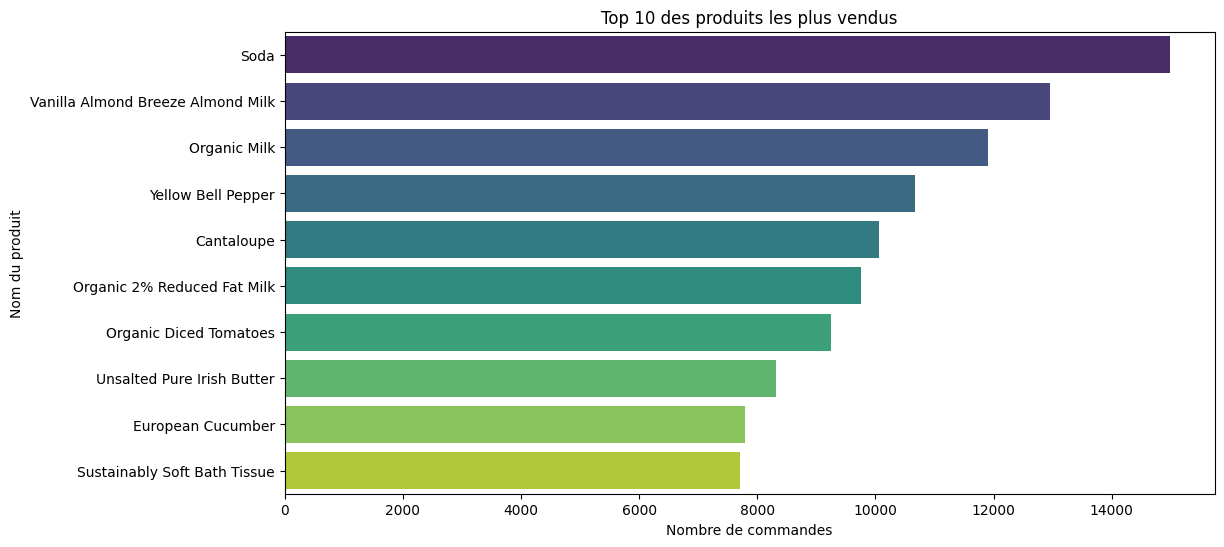

In [70]:
best_products = df_clean['product_name'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=best_products.values, y=best_products.index, palette='viridis')
plt.title('Top 10 des produits les plus vendus')
plt.xlabel('Nombre de commandes')
plt.ylabel('Nom du produit')
plt.show()

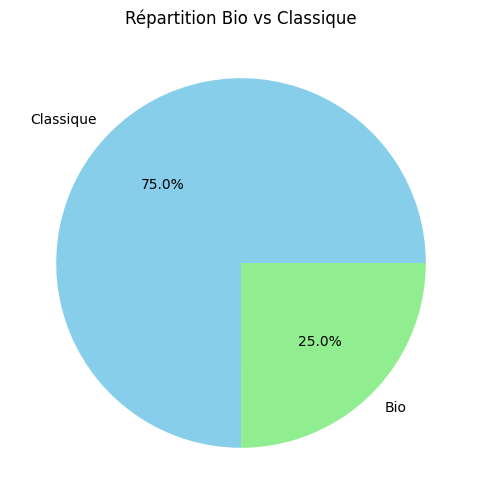

In [71]:
# Prépare les données
vegetables = df_clean[df_clean['department'] == 'produce'].copy()
# Créer une colonne avec des noms au lieu de True/False
vegetables['Type'] = vegetables['product_name'].str.contains('organic', case=False).map({True: 'Bio', False: 'Classique'})

#Affiche le graphique
plt.figure(figsize=(6, 6))
vegetables['Type'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['skyblue', 'lightgreen'])
plt.title('Répartition Bio vs Classique')
plt.ylabel('') 
plt.show()

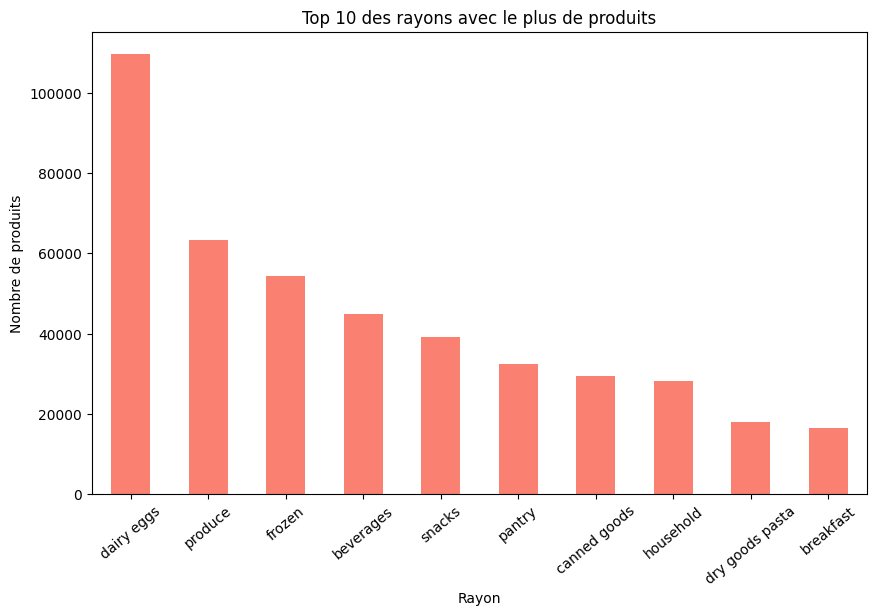

In [72]:
# Compte le nombre de produits par rayon
top_rayons = df_clean['department'].value_counts().head(10)

# Affiche le graphique en barre
plt.figure(figsize=(10, 6))
top_rayons.plot(kind='bar', color='salmon')
plt.title('Top 10 des rayons avec le plus de produits')
plt.xlabel('Rayon')
plt.ylabel('Nombre de produits')
plt.xticks(rotation=40) 
plt.show()

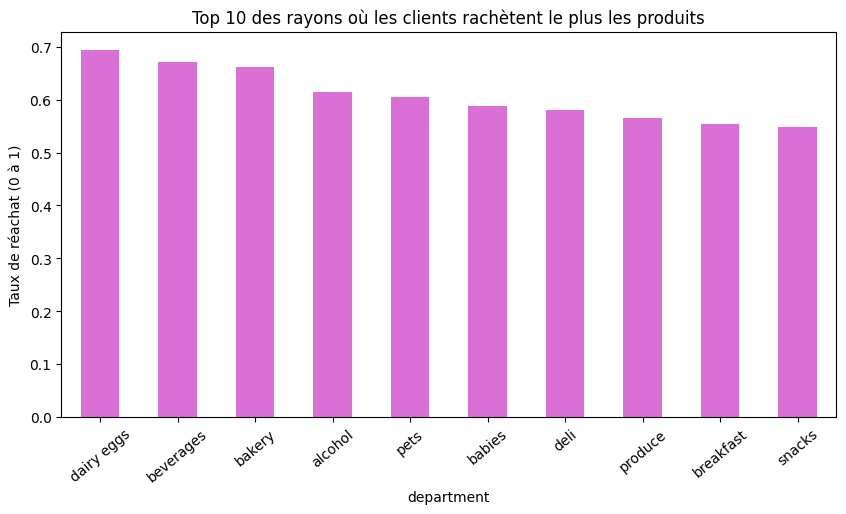

In [73]:
# Calcule le taux de réachat par rayon
reorder_r = df_clean.groupby('department')['reordered'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
reorder_r.plot(kind='bar', color='orchid')
plt.title('Top 10 des rayons où les clients rachètent le plus les produits')
plt.ylabel('Taux de réachat (0 à 1)')
plt.xticks(rotation=40) 
plt.show()